# Praktikum 1: DBSCAN dan HDBSCAN data kafe

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import hdbscan
from sklearn.cluster import DBSCAN

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(X[ci, 0], X[ci, 1], 'x' if k == -1 else 'o',
                    markerfacecolor=tuple(col), markeredgecolor='k',
                    markersize=4 if k == -1 else 1 + 5 * proba_map[ci])
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = 'Label pembanding' if ground_truth else 'Estimated'
    title = f'{preamble} number of clusters: {n_clusters_}'
    if parameters is not None:
        title += ' | ' + ', '.join(f'{k}={v}' for k, v in parameters.items())
    ax.set_title(title)
    plt.tight_layout()

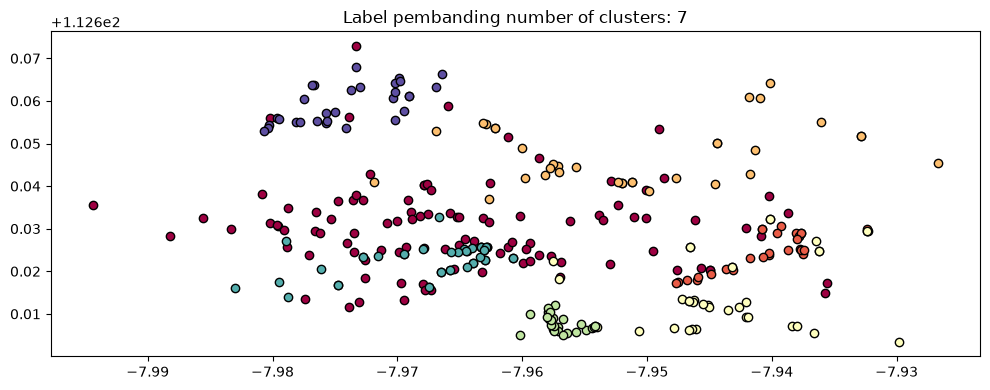

In [3]:
import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
X = df[['latitude', 'longitude']].to_numpy()
labels_true = pd.factorize(df['source_query'].fillna('Tidak tersedia'))[0]
plot(X, labels_true, ground_truth=True)

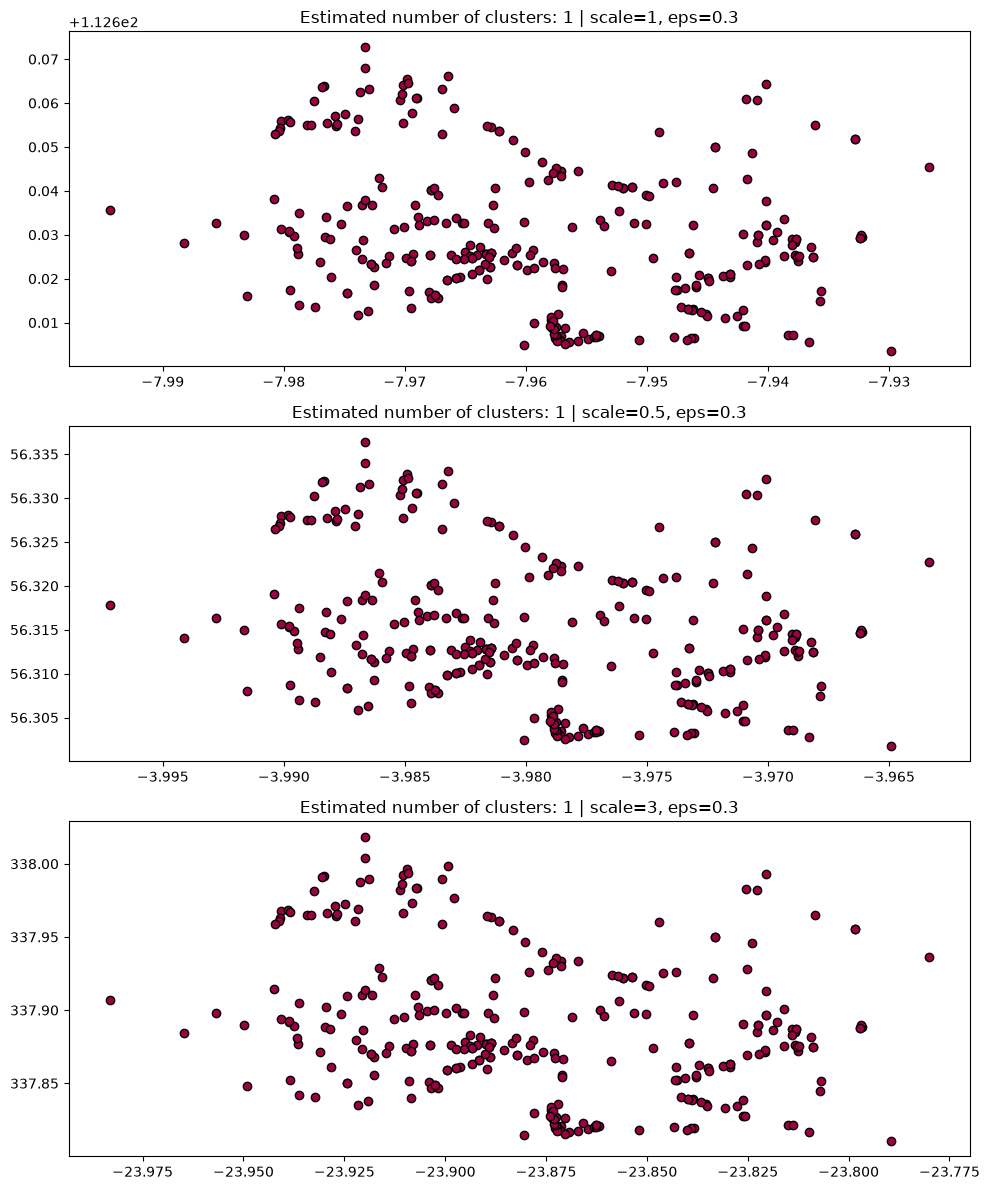

In [4]:
# Langkah 4: Uji Scale Invariance pada DBSCAN

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

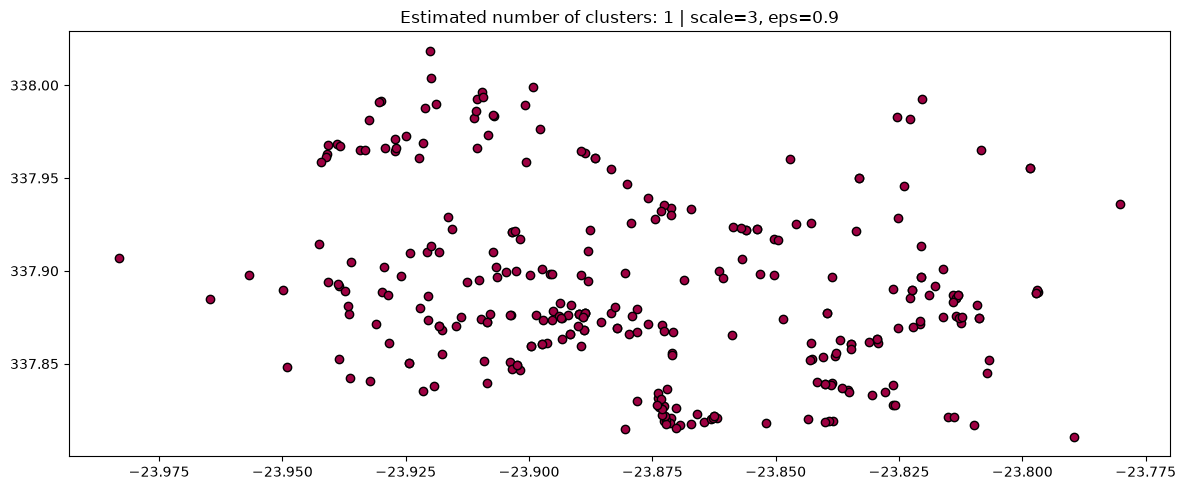

In [5]:
# Perbaiki dengan mengubah eps sesuai skala:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

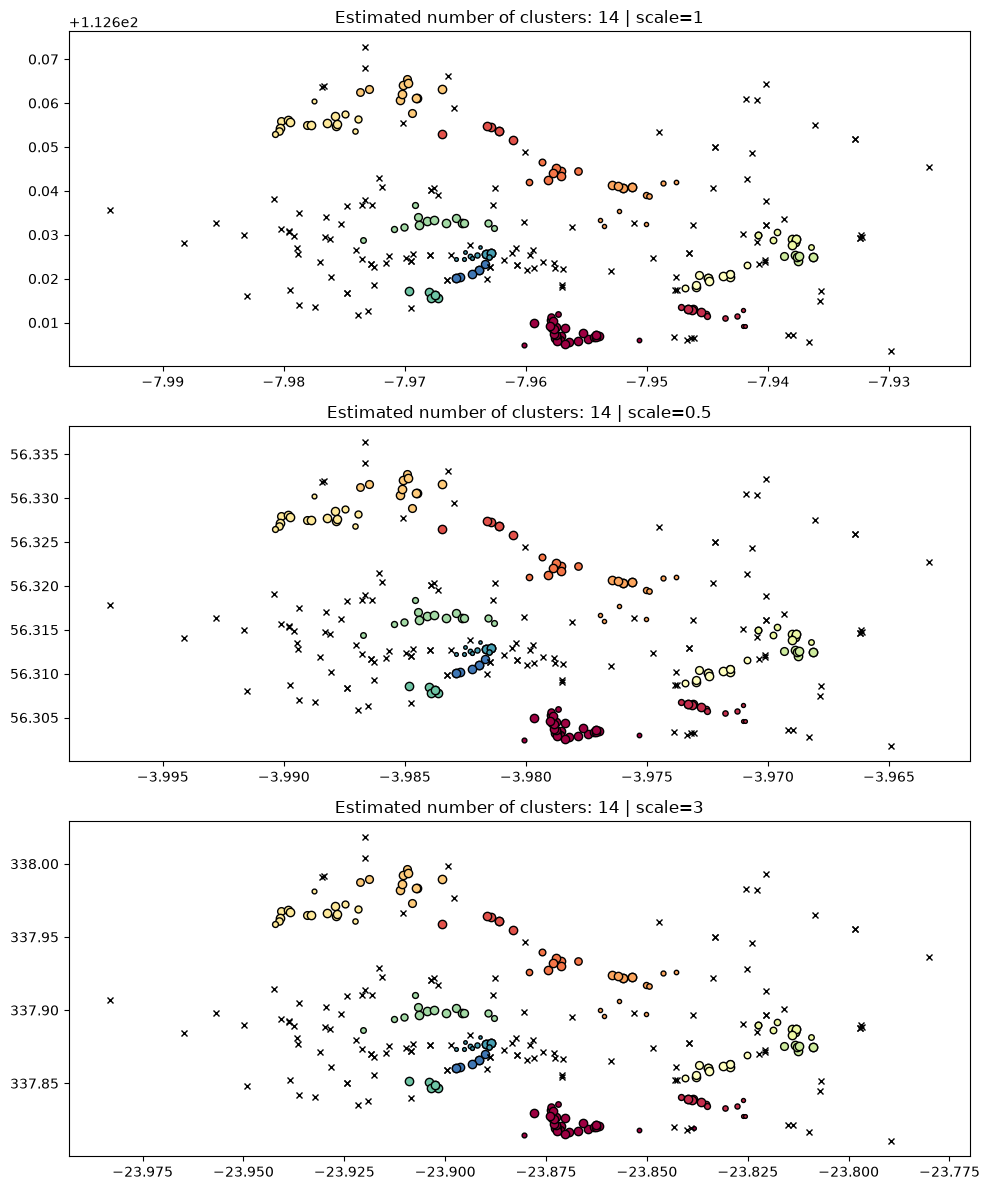

In [6]:
# Langkah 5: Bandingkan dengan HDBSCAN (lebih robust)

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

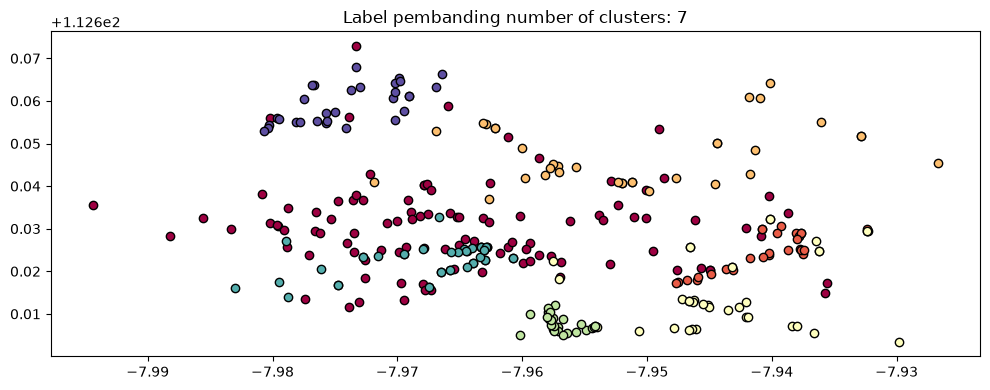

In [7]:
# Data kafe tetap dipakai pada tahap multi-scale
plot(X, labels_true, ground_truth=True)

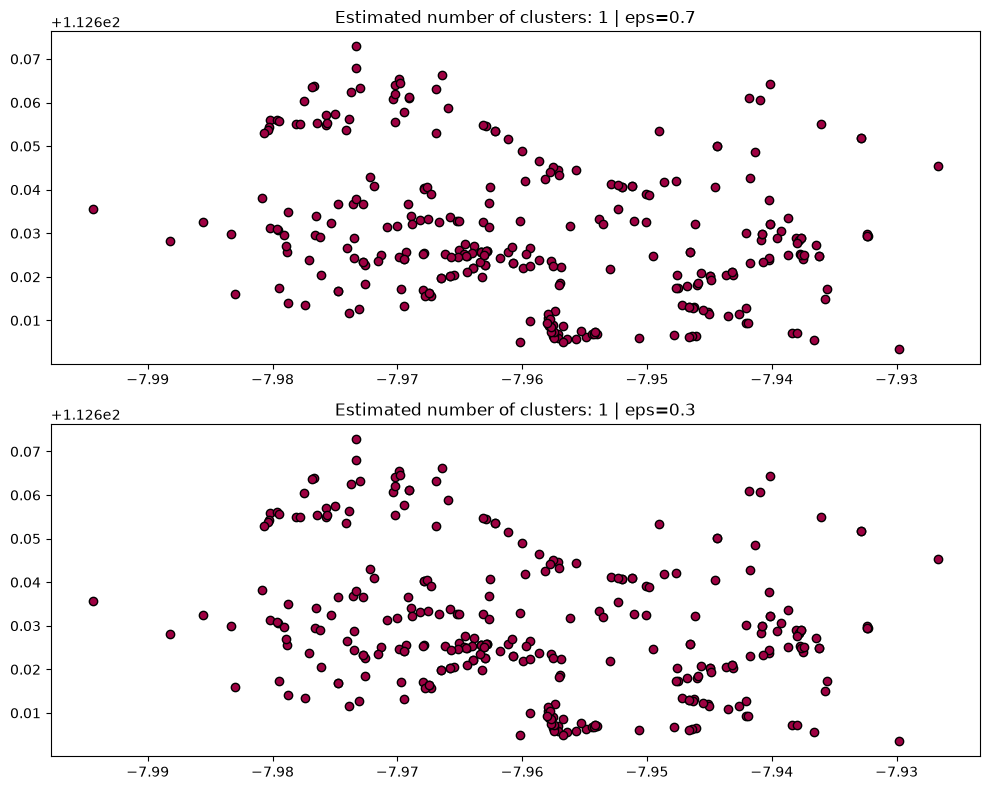

In [8]:
# Bandingkan DBSCAN dengan eps berbeda:

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

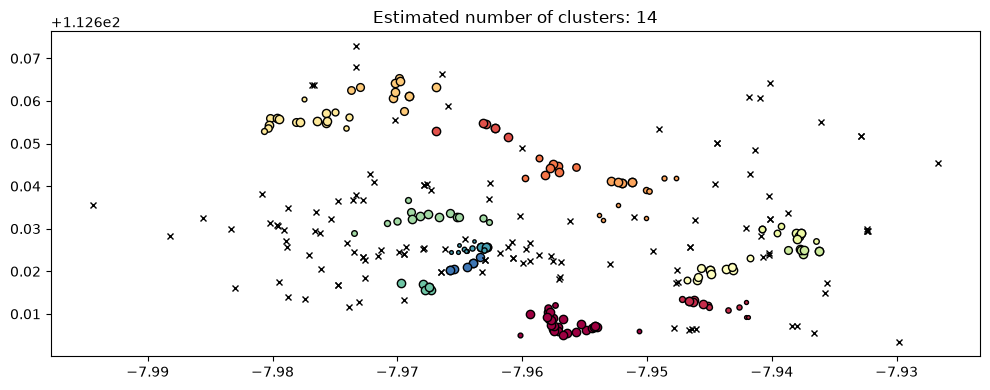

In [9]:
# Jalankan HDBSCAN:

hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)